# Task 1 - N-Queens: Propositional Logic and Local Search

This notebook runs the solvers in `nqueens/` and keeps the outputs of every cell.
Full-size experiments: `python main.py experiment-sat` and `python main.py experiment-minconflicts`.

In [1]:
import platform, sys
from nqueens.encoding import CnfEncoder
from nqueens.sat_solver import Glucose3QueensSolver
from nqueens.min_conflicts import MinConflictsSolver, RandomConflictedSelector, MostConflictedTabuSelector
from nqueens.experiments import SatExperiment, MinConflictsExperiment, machine_description
print(machine_description())

Linux-6.18.44-fc-v470-x86_64-with-glibc2.39 | x86_64 x86_64 | Python 3.13.18


## Requirement 1 - CNF model

One variable per square, `var(r, c) = r*N + c + 1`. Rows and columns: exactly one queen. Diagonals: at most one queen. Check that the clause count matches the closed form 2N + 2N*C(N,2) + 2*C(N,2) + 4*C(N,3).

In [2]:
for n in (4, 8, 12, 20):
    f = CnfEncoder(n).encode()
    print(f'N={n:3d}  variables={f.num_variables:5d}  clauses={f.num_clauses:7d}  formula={CnfEncoder.expected_clause_count(n):7d}')

N=  4  variables=   16  clauses=     84  formula=     84
N=  8  variables=   64  clauses=    744  formula=    744
N= 12  variables=  144  clauses=   2620  formula=   2620
N= 20  variables=  400  clauses=  12580  formula=  12580


## Requirement 2 - Glucose3

In [3]:
result = Glucose3QueensSolver().solve(8)
print(result.placement.render())
print('valid solution:', result.placement.is_solution())

. . . Q . . . .
. Q . . . . . .
. . . . . . Q .
. . Q . . . . .
. . . . . Q . .
. . . . . . . Q
. . . . Q . . .
Q . . . . . . .
valid solution: True


In [4]:
sat_table = SatExperiment(sizes=(4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80), repeats=3).run()
print(sat_table)

 N | variables | clauses | formula_N3 | encode_ms | load_ms | solve_ms | total_ms | conflicts | decisions | valid
---+-----------+---------+------------+-----------+---------+----------+----------+-----------+-----------+------
 4 |        16 |      84 |         84 |     0.035 |   0.058 |    0.008 |    0.106 |         2 |         6 |  True
 5 |        25 |     170 |        170 |     0.057 |   0.064 |    0.006 |    0.118 |         0 |         8 |  True
 6 |        36 |     302 |        302 |     0.090 |   0.086 |    0.020 |    0.201 |         7 |        18 |  True
 8 |        64 |     744 |        744 |     0.122 |   0.177 |    0.072 |    0.383 |        20 |        37 |  True
10 |       100 |    1490 |       1490 |     0.202 |   0.374 |    0.066 |    0.645 |        15 |        40 |  True
12 |       144 |    2620 |       2620 |     0.396 |   0.693 |    0.204 |    1.258 |        42 |        80 |  True
15 |       225 |    5210 |       5210 |     0.675 |   1.256 |    1.002 |    2.936 |     

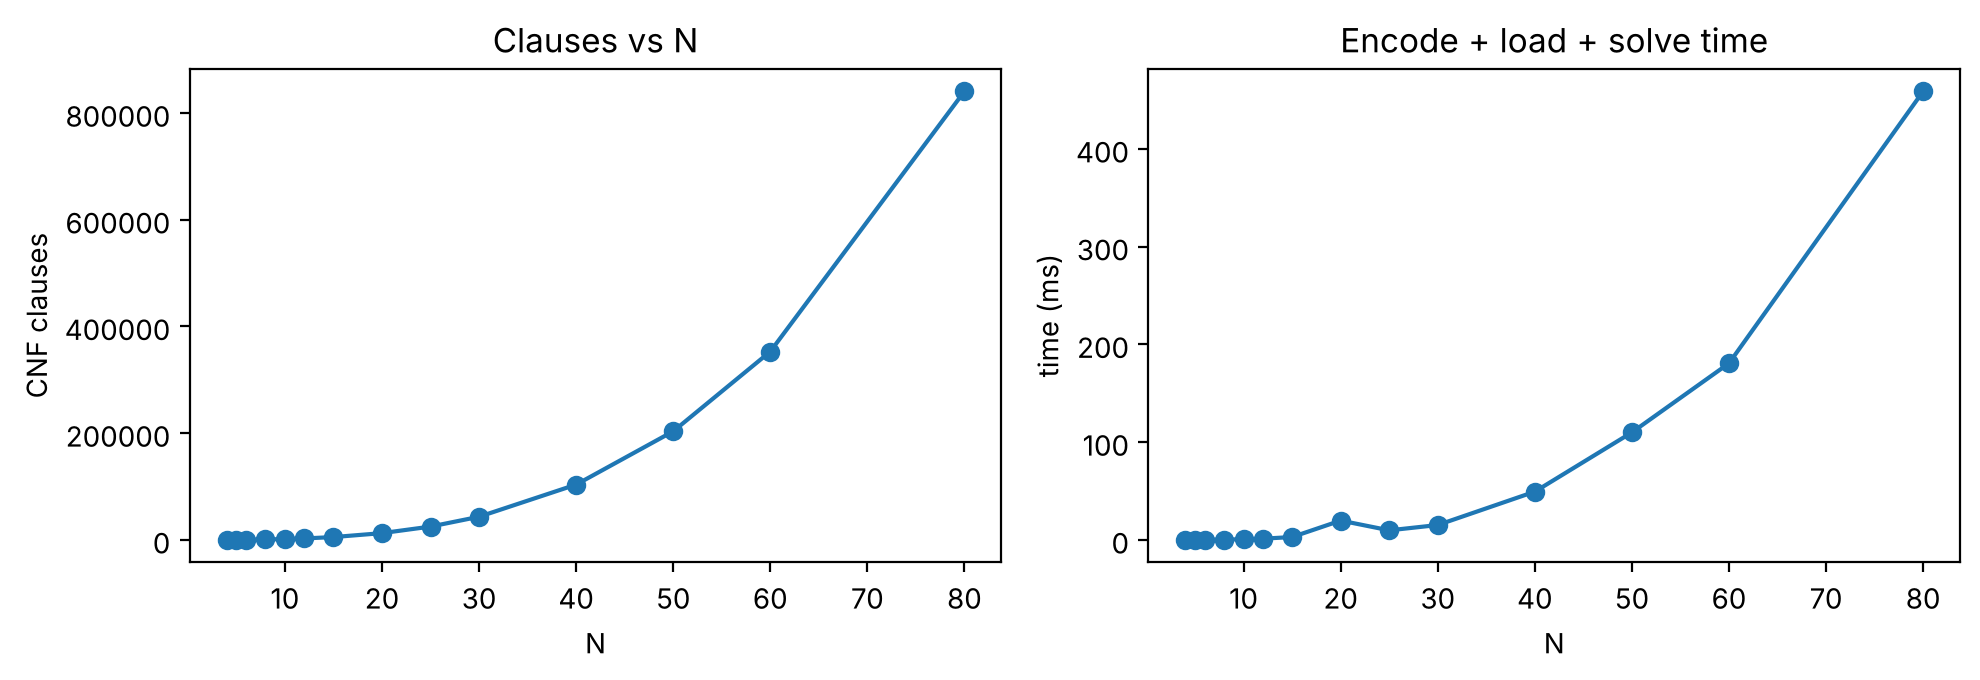

In [5]:
import matplotlib.pyplot as plt
cols = sat_table.columns
N = [r[cols.index('N')] for r in sat_table.rows]
clauses = [r[cols.index('clauses')] for r in sat_table.rows]
total = [r[cols.index('total_ms')] for r in sat_table.rows]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(N, clauses, 'o-'); ax[0].set_xlabel('N'); ax[0].set_ylabel('CNF clauses'); ax[0].set_title('Clauses vs N')
ax[1].plot(N, total, 'o-'); ax[1].set_xlabel('N'); ax[1].set_ylabel('time (ms)'); ax[1].set_title('Encode + load + solve time')
plt.tight_layout(); plt.show()

## Requirement 3 - Min-Conflicts: standard vs proposed heuristic (most-conflicted + tabu)

Each seed gives the same initial assignment to every strategy. Smaller run than the report (30 seeds).

In [6]:
for selector in (RandomConflictedSelector(), MostConflictedTabuSelector()):
    r = MinConflictsSolver(selector).solve_with_restarts(8, seed=1)
    print(f'{r.selector:22s} solved={r.solved} steps={r.steps}')

standard               solved=True steps=12
most-conflicted+tabu   solved=True steps=7


In [7]:
mc_table = MinConflictsExperiment(sizes=(8, 16, 64, 256, 1024), seeds=30).run()
print(mc_table)

   N |             selector | success_pct | steps_mean | steps_median | steps_std | ms_mean | ms_median | fewer_steps_than_standard_pct
-----+----------------------+-------------+------------+--------------+-----------+---------+-----------+------------------------------
   8 |             standard |     100.000 |     57.367 |       38.000 |    60.169 |   0.185 |     0.116 |                             -
   8 | most-conflicted+tabu |     100.000 |     19.467 |       14.500 |    16.550 |   0.097 |     0.075 |                        73.333
  16 |             standard |     100.000 |     89.900 |       67.500 |    69.380 |   0.344 |     0.265 |                             -
  16 | most-conflicted+tabu |      96.667 |    107.733 |       28.000 |   353.981 |   0.515 |     0.183 |                        66.667
  64 |             standard |     100.000 |    113.567 |      107.000 |    38.699 |   0.828 |     0.764 |                             -
  64 | most-conflicted+tabu |     100.000 |     